In [3]:
import pandas as pd
import zipfile

# Programmatically extract the zip file containing the dataset
zip_path = "/content/sms+spam+collection.zip"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/")

# Load the now extracted dataset
df = pd.read_csv(
    "/content/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset shape:", df.shape)

print("\nFirst 5 messages:")
print(df.head())

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

FileNotFoundError: [Errno 2] No such file or directory: '/content/sms+spam+collection.zip:'

In [4]:
import os
print(os.listdir("/content"))

['.config', 'sms+spam+collection.zip', 'sample_data']


In [5]:
import zipfile
import os

zip_path = "/content/sms+spam+collection.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/")

print("Files extracted successfully!")
print(os.listdir("/content"))

Files extracted successfully!
['.config', 'sms+spam+collection.zip', 'readme', 'SMSSpamCollection', 'sample_data']


In [6]:
import pandas as pd

df = pd.read_csv(
    "/content/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset shape:", df.shape)
print(df.head())
print(df["label"].value_counts())

Dataset shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64


In [7]:
import pandas as pd
import os

print("Files:", os.listdir("/content"))

df = pd.read_csv(
    "/content/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("\nDataset shape:", df.shape)

print("\nFirst 5 messages:")
print(df.head())

print("\nSpam and Ham counts:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Files: ['.config', 'sms+spam+collection.zip', 'readme', 'SMSSpamCollection', 'sample_data']

Dataset shape: (5572, 2)

First 5 messages:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Spam and Ham counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


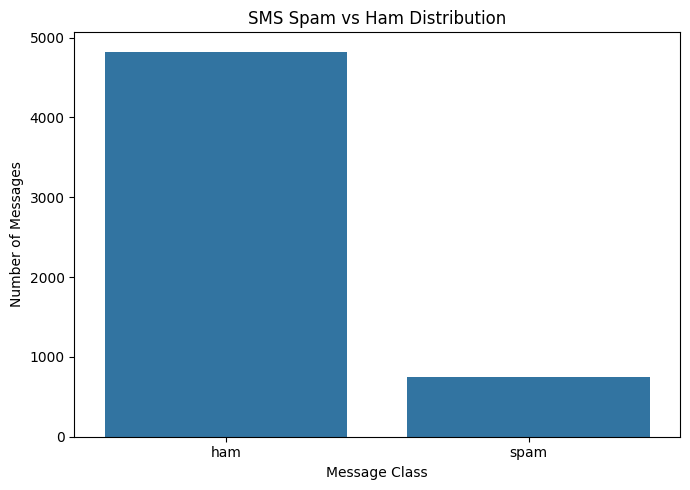

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count messages in each class
class_counts = df["label"].value_counts()

print("Class Distribution:")
print(class_counts)

# Create bar chart
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label")

plt.title("SMS Spam vs Ham Distribution")
plt.xlabel("Message Class")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()

In [9]:
import re

# Check missing and duplicate records
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove missing rows and duplicate records
df = df.dropna(subset=["label", "message"]).copy()
df = df.drop_duplicates().copy()

# Text cleaning function
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)       # Remove HTML tags
    text = re.sub(r"[^a-z0-9\s]", " ", text) # Remove punctuation
    text = re.sub(r"\s+", " ", text).strip() # Remove extra spaces
    return text

df["clean_message"] = df["message"].apply(clean_text)

print("\nCleaned dataset preview:")
print(df[["label", "message", "clean_message"]].head())

print("\nDataset shape after cleaning:", df.shape)

Missing values before cleaning:
label      0
message    0
dtype: int64

Duplicate rows: 403

Cleaned dataset preview:
  label                                            message  \
0   ham  Go until jurong point, crazy.. Available only ...   
1   ham                      Ok lar... Joking wif u oni...   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...   
3   ham  U dun say so early hor... U c already then say...   
4   ham  Nah I don't think he goes to usf, he lives aro...   

                                       clean_message  
0  go until jurong point crazy available only in ...  
1                            ok lar joking wif u oni  
2  free entry in 2 a wkly comp to win fa cup fina...  
3        u dun say so early hor u c already then say  
4  nah i don t think he goes to usf he lives arou...  

Dataset shape after cleaning: (5169, 3)


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Input and target
X = df["clean_message"]
y = df["label"]

# Same train-test split for all four algorithms
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert text into TF-IDF numerical features
tfidf = TfidfVectorizer(max_features=3000)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of TF-IDF features:", X_train.shape[1])

Training samples: 4135
Testing samples: 1034
Number of TF-IDF features: 3000


In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# Create four classifiers
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ),
    "Naive Bayes": MultinomialNB()
}

# Train all four models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

print("\nAll four models trained successfully.")

Decision Tree trained successfully!
KNN trained successfully!
SVM trained successfully!
Naive Bayes trained successfully!

All four models trained successfully.


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("MODEL COMPARISON RESULTS")
display(results_df.round(4))

MODEL COMPARISON RESULTS


,Algorithm,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.9671,0.9145,0.8168,0.8629
1,KNN,0.9139,1.0000,0.3206,0.4855
2,SVM,0.9787,0.9580,0.8702,0.9120
3,Naive Bayes,0.9681,1.0000,0.7481,0.8559


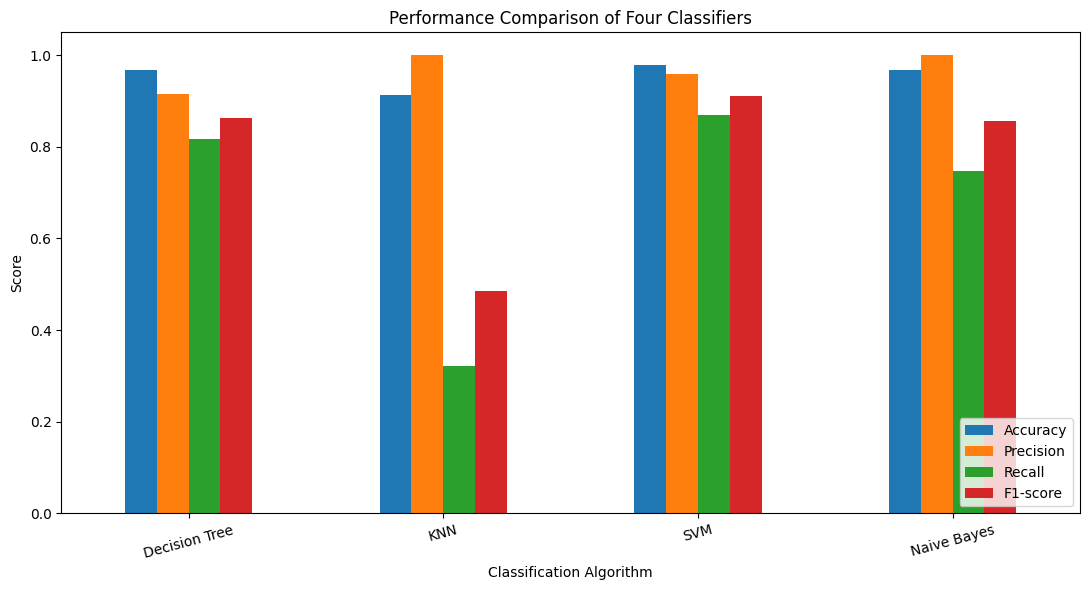

In [13]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Four Classifiers")
plt.xlabel("Classification Algorithm")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

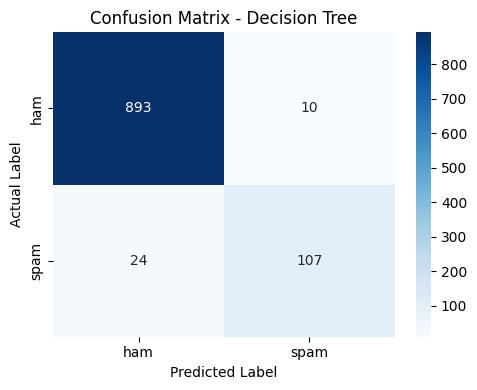

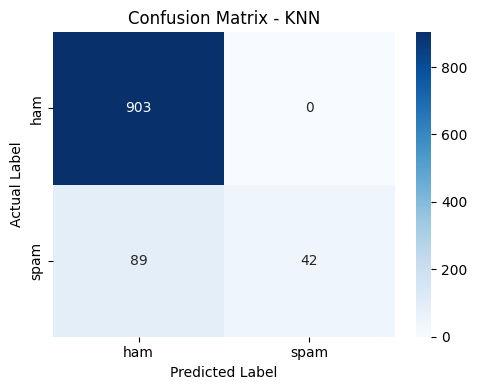

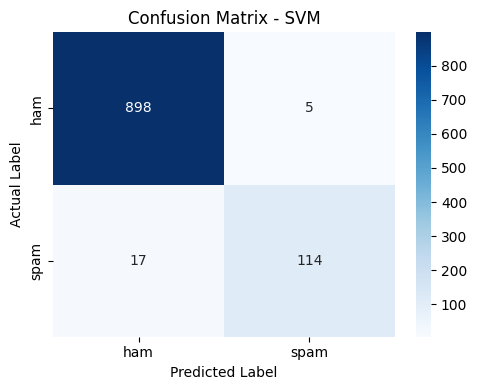

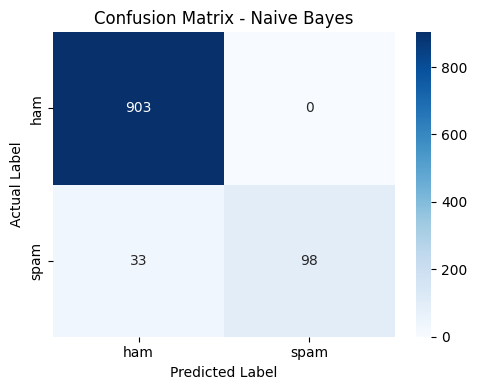

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

for name, y_pred in predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

In [15]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

what_if_results = []

for c_value in [0.1, 1.0, 10.0]:
    svm_model = LinearSVC(
        C=c_value,
        random_state=42,
        max_iter=5000
    )

    svm_model.fit(X_train, y_train)
    pred = svm_model.predict(X_test)

    what_if_results.append({
        "SVM C": c_value,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, pos_label="spam", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, pos_label="spam", zero_division=0
        )
    })

what_if_df = pd.DataFrame(what_if_results)
display(what_if_df.round(4))

,SVM C,Accuracy,Precision,Recall,F1-score
0,0.1,0.9700,0.9717,0.7863,0.8692
1,1.0,0.9787,0.9580,0.8702,0.9120
2,10.0,0.9787,0.9360,0.8931,0.9141


In [16]:
best_row = results_df.loc[results_df["F1-score"].idxmax()]

print("Best model based on Spam F1-score:")
print(best_row["Algorithm"])
print("F1-score:", round(best_row["F1-score"], 4))

Best model based on Spam F1-score:
SVM
F1-score: 0.912
